# 03 · Estudio de diseño, menos tránsitos y sistema conjunto

**Proyecto del curso de Deep Learning** · Juan Sebastian Higuita Riascos · Universidad Nacional de Colombia

El notebook 02 varió hiperparámetros **numéricos**. Este responde lo que faltaba: ¿y si se cambia una **decisión de diseño**?

| Sección | Pregunta |
|---|---|
| 1 | ¿Qué se probó y qué no? |
| 2 | ¿Qué pasa al cambiar una sola decisión? (activación, normalización, optimizador, profundidad, pérdida, preprocesamiento) |
| 3 | ¿Las mejoras de la rama 1 se confirman con 3 semillas? |
| 4 | ¿Qué aportan los estadísticos entre tránsitos? ¿Y qué pasa con menos tránsitos? |
| 5 | El sistema conjunto y la prueba de extremo a extremo |
| 6 | Conclusiones y lo que queda por decidir |

Este notebook **no entrena**: lee `resultados/dl/diseno/`, `resultados/dl/e4/` y `resultados/dl/e2e/`. La sección 5 sí ejecuta el sistema (solo inferencia).

In [1]:
import sys
import warnings
from pathlib import Path

from IPython.display import display

warnings.filterwarnings("ignore")

RAIZ = next(
    carpeta
    for carpeta in [Path.cwd(), *Path.cwd().parents]
    if (carpeta / "config" / "protocolo.json").is_file()
)
sys.path.insert(0, str(RAIZ / "src"))

from informe import datos, diseno, graficos
from informe.interactivo import Lista, controles

graficos.aplicar_estilo()
res = datos.cargar(RAIZ)
MODELOS = [(diseno.NOMBRE[a], a) for a in diseno.disponibles(res)]
print("Modelos con estudio de diseño:", ", ".join(nombre for nombre, _ in MODELOS))

Modelos con estudio de diseño: Rama 1 · CNN tipo AstroNet, Rama 2 · atención, Rama 4 · escalares


## 1 · Qué se probó y qué no

Cada variante cambia **una sola cosa** respecto al protocolo y se entrena con el mismo motor, las mismas particiones y la semilla 0. La comparación es la diferencia pareada de AUC en prueba, con su intervalo del 95 %.

| Factor | Protocolo | Variantes probadas |
|---|---|---|
| Activación | ReLU | GELU, tanh |
| Normalización | ninguna | por lote (BatchNorm), por capa (LayerNorm) |
| Optimizador | AdamW | Adam sin decaimiento, SGD con momento de Nesterov |
| Profundidad | 2–3 bloques (ramas 1 y 2), 1 capa oculta (rama 4) | una capa o bloque menos, una más |
| Pérdida | entropía cruzada con pesos por clase | sin pesos, suavizado de etiquetas 0,1, focal γ = 2 |
| Preprocesamiento | unidades de profundidad + aumentación | sin aumentación, *z-score* por serie; rama 4 sin estandarizar |
| Pooling (rama 1) | máximo | promedio, convolución con paso 2 |
| Entradas (rama 2) | con 4 estadísticos de consistencia | sin ellos |

**No se probó:** combinaciones de factores, otras familias de arquitectura (por ejemplo un Transformer completo o una BiGRU sobre la curva plegada), ajuste fino conjunto de las ramas ni un ensamble de codificadores. Tampoco existe una variante "sin banderas de dato faltante": rellenar con 0 sin avisar va contra las reglas del proyecto.

> **Cómo leer todo lo que sigue.** Son unas 15 comparaciones por modelo con una sola semilla. Con ese número, que alguna "se distinga de cero" por puro azar es esperable. Por eso se fijó de antemano (spec 010) que una variante solo cuenta si además se **confirma con 3 semillas**.

## 2 · ¿Qué pasa al cambiar una sola decisión?

**Cómo leer la figura.** Cada fila es una variante. El punto es cuánto cambia el AUC respecto al protocolo; a la derecha de 0 mejora, a la izquierda empeora. En verde, las que se distinguen de cero.

**Prueba esto.** Cambia de modelo: las tres ramas no reaccionan igual.

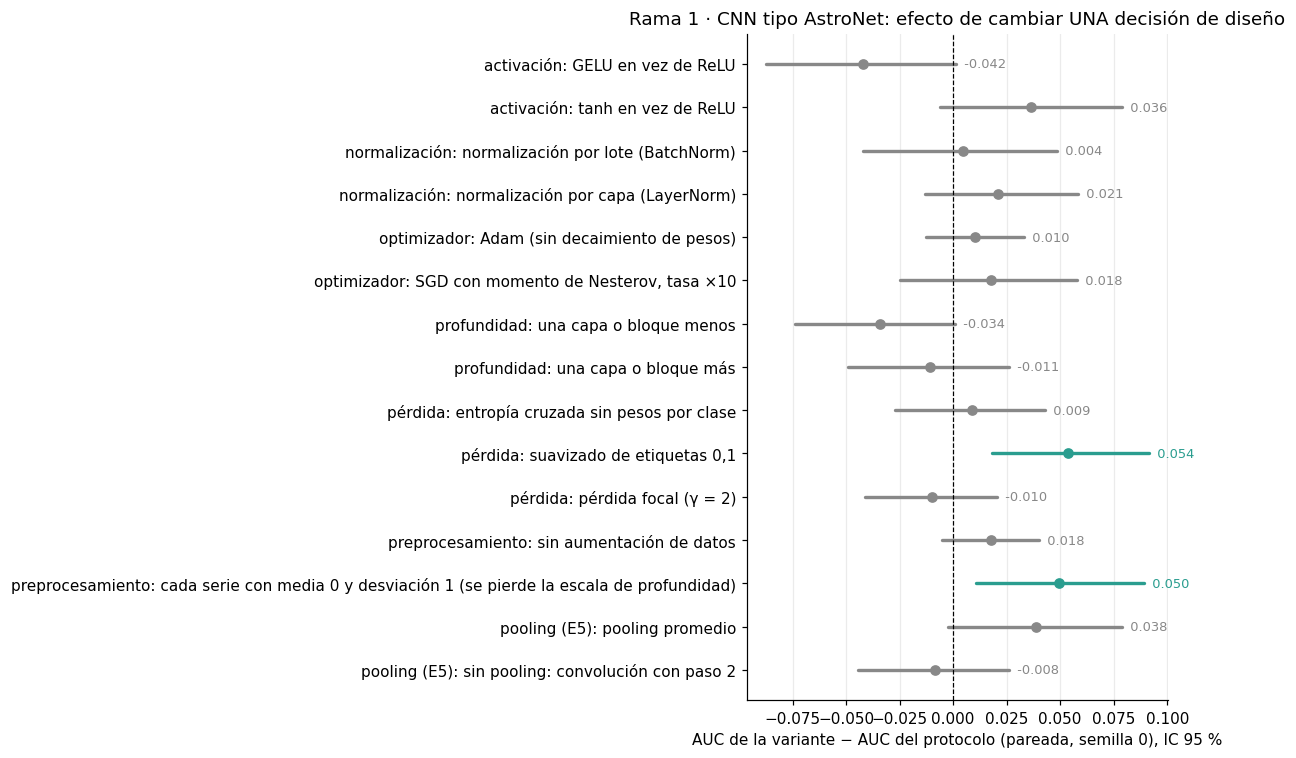

Protocolo: AUC 0.881 · NLL de validación 0.385 · 57747 parámetros


,factor,cambio,parametros,epocas_medias,nll_validacion,auc_prueba,diferencia_auc,ic_inf,ic_sup,distinguible
0,activación,GELU en vez de ReLU,57747,18.8,0.4277,0.8390,-0.0420,-0.0874,0.0013,False
1,activación,tanh en vez de ReLU,57747,27.0,0.2753,0.9174,0.0364,-0.0059,0.0788,False
2,normalización,normalización por lote (BatchNorm),58387,39.8,0.3857,0.8855,0.0045,-0.0421,0.0485,False
3,normalización,normalización por capa (LayerNorm),58067,17.6,0.3020,0.9018,0.0208,-0.0132,0.0585,False
4,optimizador,Adam (sin decaimiento de pesos),57747,25.4,0.3658,0.8914,0.0104,-0.0126,0.0332,False
5,optimizador,"SGD con momento de Nesterov, tasa ×10",57747,36.2,0.3858,0.8987,0.0177,-0.0248,0.0577,False
6,profundidad,una capa o bloque menos,16083,23.2,0.3535,0.8470,-0.0340,-0.0739,0.0008,False
7,profundidad,una capa o bloque más,217875,19.6,0.3860,0.8703,-0.0107,-0.0492,0.0263,False
8,pérdida,entropía cruzada sin pesos por clase,57747,23.6,0.3706,0.8900,0.0090,-0.0269,0.0431,False
9,pérdida,"suavizado de etiquetas 0,1",57747,59.4,0.3362,0.9346,0.0536,0.0182,0.0914,True


(Vista fija con Modelo: m1_astronet. Ejecuta el notebook para usar los controles.)


In [2]:
controles(
    lambda arquitectura: diseno.efecto_de_cada_decision(res, arquitectura),
    arquitectura=Lista("Modelo:", MODELOS, inicial="m1_astronet"),
)

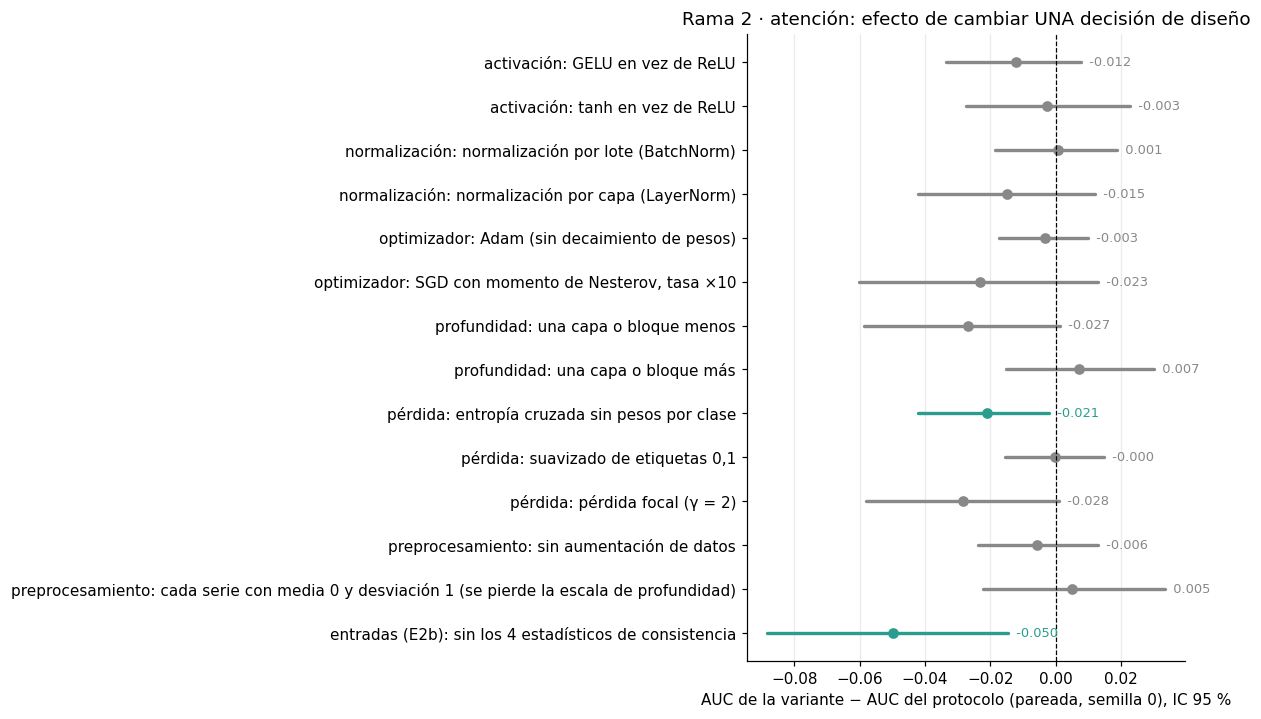

Protocolo: AUC 0.891 · NLL de validación 0.465 · 13604 parámetros


,factor,cambio,parametros,epocas_medias,nll_validacion,auc_prueba,diferencia_auc,ic_inf,ic_sup,distinguible
0,activación,GELU en vez de ReLU,13604,38.8,0.4615,0.8791,-0.0120,-0.0335,0.0077,False
1,activación,tanh en vez de ReLU,13604,46.2,0.4427,0.8884,-0.0028,-0.0276,0.0227,False
2,normalización,normalización por lote (BatchNorm),13796,28.4,0.4563,0.8918,0.0007,-0.0185,0.0189,False
3,normalización,normalización por capa (LayerNorm),13700,32.4,0.4647,0.8764,-0.0148,-0.0422,0.0122,False
4,optimizador,Adam (sin decaimiento de pesos),13604,29.0,0.4651,0.8880,-0.0032,-0.0172,0.0100,False
5,optimizador,"SGD con momento de Nesterov, tasa ×10",13604,34.6,0.4702,0.8681,-0.0231,-0.0603,0.0131,False
6,profundidad,una capa o bloque menos,10500,35.8,0.4696,0.8642,-0.0270,-0.0588,0.0014,False
7,profundidad,una capa o bloque más,24932,32.4,0.4362,0.8984,0.0072,-0.0151,0.0301,False
8,pérdida,entropía cruzada sin pesos por clase,13604,40.0,0.4445,0.8701,-0.0211,-0.0423,-0.0021,True
9,pérdida,"suavizado de etiquetas 0,1",13604,40.2,0.4745,0.8909,-0.0003,-0.0155,0.0148,False


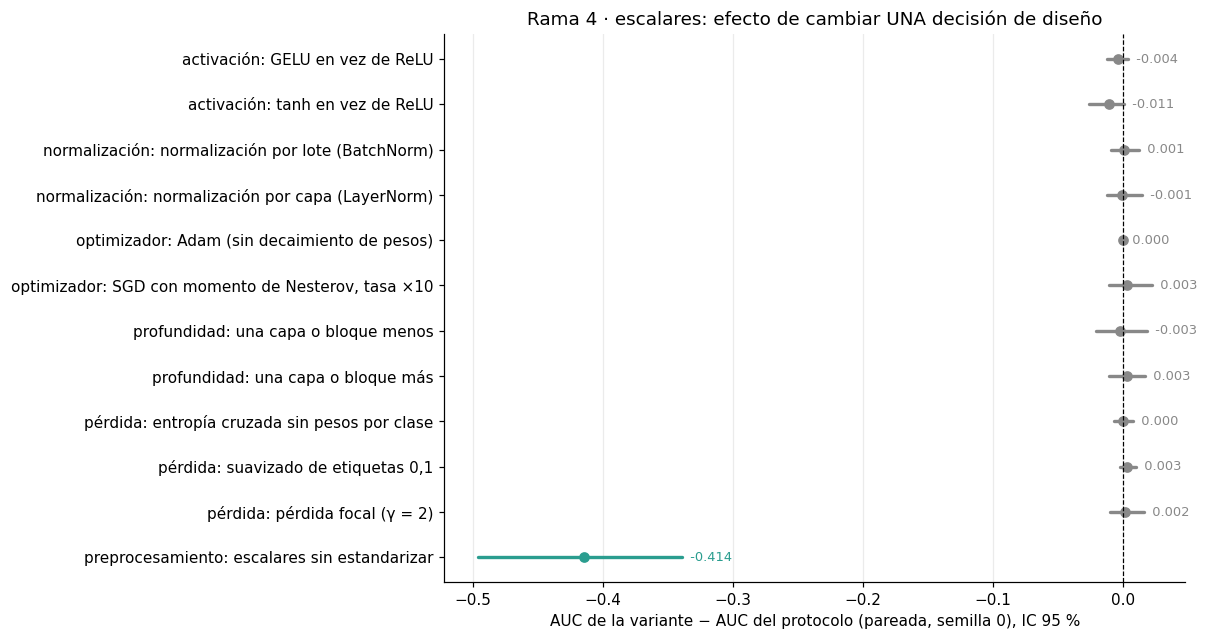

Protocolo: AUC 0.957 · NLL de validación 0.198 · 1059 parámetros


,factor,cambio,parametros,epocas_medias,nll_validacion,auc_prueba,diferencia_auc,ic_inf,ic_sup,distinguible
0,activación,GELU en vez de ReLU,1059,81.2,0.2021,0.9535,-0.0038,-0.0119,0.0041,False
1,activación,tanh en vez de ReLU,1059,95.2,0.1897,0.9465,-0.0108,-0.0261,0.0007,False
2,normalización,normalización por lote (BatchNorm),1187,75.6,0.1837,0.9584,0.0011,-0.0090,0.0125,False
3,normalización,normalización por capa (LayerNorm),1123,56.0,0.2022,0.9566,-0.0007,-0.0125,0.0143,False
4,optimizador,Adam (sin decaimiento de pesos),1059,78.6,0.1979,0.9574,0.0001,-0.0005,0.0007,False
5,optimizador,"SGD con momento de Nesterov, tasa ×10",1059,53.4,0.1884,0.9607,0.0034,-0.0110,0.0220,False
6,profundidad,una capa o bloque menos,291,136.4,0.2072,0.9548,-0.0025,-0.0210,0.0188,False
7,profundidad,una capa o bloque más,2115,60.2,0.1857,0.9603,0.0030,-0.0104,0.0169,False
8,pérdida,entropía cruzada sin pesos por clase,1059,75.2,0.1946,0.9575,0.0002,-0.0067,0.0074,False
9,pérdida,"suavizado de etiquetas 0,1",1059,93.4,0.2359,0.9603,0.0029,-0.0026,0.0097,False


In [3]:
# Las otras dos ramas, fijas, para poder comparar sin ejecutar
display(diseno.efecto_de_cada_decision(res, "m2_atencion"))
display(diseno.efecto_de_cada_decision(res, "m4_escalares"))

**Lectura.**

- **Rama 4 (escalares):** nada la mejora ni la empeora de forma distinguible, salvo quitar la estandarización, que la destruye. Es un modelo tan pequeño que estas decisiones no importan; la estandarización sí es imprescindible.
- **Rama 2 (atención):** ninguna variante la mejora. Dos la empeoran de forma distinguible: entrenar **sin pesos por clase** y quitar los **estadísticos de consistencia**.
- **Rama 1 (AstroNet):** es la que más reacciona. Con una semilla, dos variantes mejoran de forma distinguible (suavizado de etiquetas y *z-score*) y varias más apuntan en la misma dirección (tanh, pooling promedio, normalización por capa). La siguiente sección comprueba si eso se sostiene.

### El mismo resumen, eligiendo con la validación

Para no elegir mirando la prueba, esta tabla toma de cada factor la variante con **mejor NLL de validación** y muestra qué le pasó en la prueba.

In [4]:
display(diseno.resumen_por_factor(res))

,modelo,factor,mejor variante en validación,¿mejora la validación?,diferencia de AUC en prueba,IC inf,IC sup,se distingue de 0
0,Rama 1 · CNN tipo AstroNet,activación,tanh en vez de ReLU,True,0.0364,-0.0059,0.0788,False
1,Rama 1 · CNN tipo AstroNet,normalización,normalización por capa (LayerNorm),True,0.0208,-0.0132,0.0585,False
2,Rama 1 · CNN tipo AstroNet,optimizador,Adam (sin decaimiento de pesos),True,0.0104,-0.0126,0.0332,False
3,Rama 1 · CNN tipo AstroNet,profundidad,una capa o bloque menos,True,-0.0340,-0.0739,0.0008,False
4,Rama 1 · CNN tipo AstroNet,pérdida,"suavizado de etiquetas 0,1",True,0.0536,0.0182,0.0914,True
5,Rama 1 · CNN tipo AstroNet,preprocesamiento,cada serie con media 0 y desviación 1 (se pier...,True,0.0496,0.0108,0.0891,True
6,Rama 1 · CNN tipo AstroNet,pooling (E5),pooling promedio,True,0.0385,-0.0026,0.0787,False
7,Rama 2 · atención,activación,tanh en vez de ReLU,True,-0.0028,-0.0276,0.0227,False
8,Rama 2 · atención,normalización,normalización por lote (BatchNorm),True,0.0007,-0.0185,0.0189,False
9,Rama 2 · atención,optimizador,Adam (sin decaimiento de pesos),False,-0.0032,-0.0172,0.0100,False


## 3 · ¿Las mejoras de la rama 1 se confirman?

Se repitieron con las 3 semillas del protocolo tres variantes de la rama 1: las dos que se distinguieron en la prueba y la mejor en validación (tanh). Se compara la media de las 3 semillas con la del protocolo, y también **sin la semilla 0**, que fue la que motivó elegirlas.

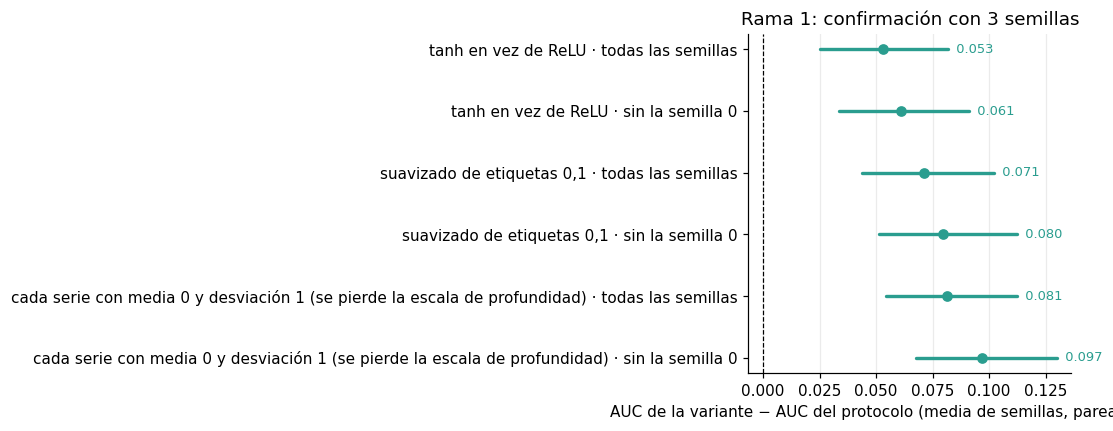

,variante,semillas,auc_variante,auc_protocolo,diferencia_auc,ic_inf,ic_sup,distinguible
0,tanh en vez de ReLU,todas las semillas,0.9174,0.8645,0.0529,0.0250,0.0819,True
1,tanh en vez de ReLU,sin la semilla 0,0.9174,0.8562,0.0612,0.0334,0.0912,True
2,"suavizado de etiquetas 0,1",todas las semillas,0.9356,0.8645,0.0711,0.0436,0.1023,True
3,"suavizado de etiquetas 0,1",sin la semilla 0,0.9361,0.8562,0.0798,0.0515,0.1126,True
4,cada serie con media 0 y desviación 1 (se pier...,todas las semillas,0.9457,0.8645,0.0812,0.0544,0.1123,True
5,cada serie con media 0 y desviación 1 (se pier...,sin la semilla 0,0.9532,0.8562,0.0970,0.0678,0.1299,True


In [5]:
display(diseno.confirmacion(res))

**Lectura.** Las tres se **confirman**: la mejora se distingue de cero con 3 semillas, y también sin la semilla que las seleccionó. La rama 1 del protocolo estaba por debajo de lo que la misma arquitectura puede dar.

**Qué significa y qué no.**

- Es un resultado **de la rama sola**. No se sabe si mejora el sistema: la fusión ya recibe por otras ramas parte de lo que estas variantes añaden. Para saberlo hay que reexportar el codificador y rehacer fusión, calibración e incertidumbre, y eso es una decisión que cambia el resultado principal del proyecto.
- **Sobre el *z-score*** (interpretación, no comprobada): el proyecto normaliza por profundidad a propósito, para que la rama 1 mire solo la *forma*. El *z-score* deja pasar además cuán fuerte es la señal respecto al ruido, que es información que ya tiene la rama 4. Parte de su ganancia puede ser esa información duplicada.
- Las variantes se eligieron mirando resultados de prueba de la semilla 0. Aunque la confirmación sin esa semilla también se sostiene, sigue siendo el mismo conjunto de estrellas.

## 4 · Estadísticos entre tránsitos y menos tránsitos

### E2b · ¿Qué pierde cada agregador sin los estadísticos de consistencia?

La rama 2 recibe, además de los tránsitos, 4 números calculados a mano (dispersión de la profundidad, diferencia impar − par, número de tránsitos y tránsito más desviado). Aquí se le quitan.

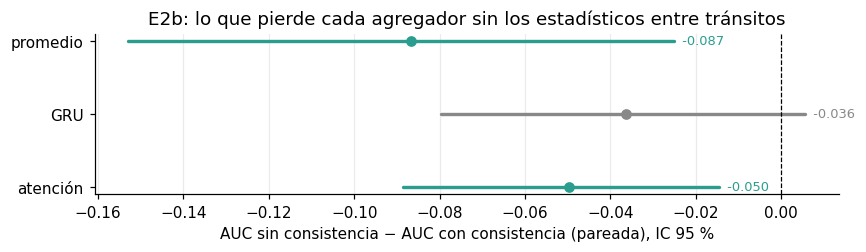

,agregador,AUC con consistencia,AUC sin consistencia,diferencia,IC inf,IC sup,se distingue de 0
0,promedio,0.8472,0.7606,-0.0866,-0.1529,-0.0251,True
1,GRU,0.8674,0.8311,-0.0363,-0.0796,0.0056,False
2,atención,0.8912,0.8413,-0.0498,-0.0885,-0.0145,True


In [6]:
display(diseno.sin_consistencia(res))

**Lectura.** El **promedio** es el que más pierde: por construcción no puede comparar un tránsito con otro, así que dependía de esos números. La **atención** también pierde de forma distinguible. La **GRU** pierde menos y su caída no se distingue de cero.

### E4 · ¿Y con menos tránsitos?

Con los modelos **sin** estadísticos de consistencia (para que lo único que cambie sea cuántos tránsitos ve el agregador), en la prueba se dejan 32, 16, 8, 4 y 2 tránsitos elegidos al azar.

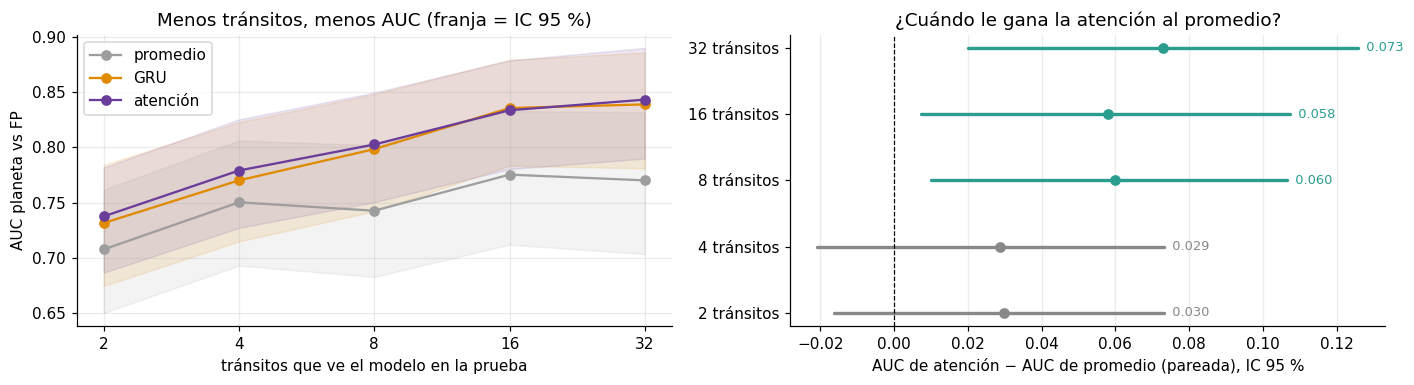

,transitos,modelo,estimacion,ic_inf,ic_sup,distinguible
0,32,atencion − promedio,0.0728,0.0200,0.1259,True
1,32,atencion − gru,0.0043,-0.0330,0.0410,False
2,16,atencion − promedio,0.0581,0.0073,0.1075,True
3,16,atencion − gru,-0.0020,-0.0374,0.0340,False
4,8,atencion − promedio,0.0598,0.0101,0.1065,True
5,8,atencion − gru,0.0042,-0.0365,0.0467,False
6,4,atencion − promedio,0.0287,-0.0208,0.0732,False
7,4,atencion − gru,0.0089,-0.0404,0.0606,False
8,2,atencion − promedio,0.0299,-0.0162,0.0733,False
9,2,atencion − gru,0.0061,-0.0540,0.0689,False


In [7]:
display(diseno.menos_transitos(res))

**Lectura.**

- **Sin los estadísticos hechos a mano, la atención sí supera al promedio** de forma distinguible con 32, 16 y 8 tránsitos. Es decir: la atención aprende sola lo que al promedio había que dárselo calculado. Frente a la GRU no hay diferencia.
- **Con 4 y 2 tránsitos la ventaja deja de distinguirse.** Es lo contrario de lo que se esperaba (que la atención ayudara más con pocos tránsitos).

**Límites.** Esto simula pocos tránsitos con señales de periodo corto, donde cada tránsito sigue siendo limpio; no es el régimen de zona habitable. Los modelos se entrenaron viendo entre 4 y 32 tránsitos, así que 2 es extrapolar. Una semilla.

## 5 · El sistema conjunto

`fusion/sistema.py` encadena las piezas tal como se usan juntas:

```
entradas ─► 4 codificadores congelados ─► cabeza de fusión ─► temperatura ─► prior explícito
```

Hay un sistema por partición. Una estrella del conjunto se responde con el de **su** partición (codificadores y cabeza que nunca la vieron); una estrella nueva, con el promedio de los cinco.

**Prueba esto.** Elige una señal y cambia la tasa base declarada.

In [8]:
senales = ["K00022.01|transito", "K03615.01|transito"]
senales += [s for s in sorted(res.ids[res.y < 2]) if s not in senales]

controles(
    lambda id_ejemplo, tasa_base: diseno.respuesta_del_sistema(res, id_ejemplo, tasa_base),
    id_ejemplo=Lista("Señal:", senales),
    tasa_base=Lista("Tasa base:", [0.05, 0.02, 0.1, 0.2, 0.5]),
)

K00022.01|transito · clase real: planeta · se usó el sistema de la partición 2
Ramas con dato: vistas, transitos, imagen, escalares


,cantidad,valor
0,P(planeta),0.9401
1,P(falso positivo),0.0590
2,P(sin señal),0.0009
3,P(planeta | hay señal),0.9409
4,P(planeta | hay señal) con tasa base 0.05,0.4258
5,entropía (duda),0.2314


(Vista fija con Señal: K00022.01|transito, Tasa base: 0.05. Ejecuta el notebook para usar los controles.)


### Prueba de extremo a extremo

`scripts/prueba_e2e.py` recorre todo el camino para estrellas elegidas al azar con semilla fija, desde los archivos FITS de Kepler, y compara con lo publicado en tres puntos: las entradas, el vector de cada rama y la probabilidad calibrada. Las columnas son la diferencia máxima en cada punto.

In [9]:
display(diseno.prueba_de_extremo_a_extremo(res))

Prueba de extremo a extremo: correcta · 10 estrellas al azar (semilla 7) · tolerancia 0.0001


,kepid,partición,entradas,vectores,probabilidad,coincide
0,11651105,0,0.0,4.768372e-07,2.252322e-07,True
1,9570741,0,0.0,5.662441e-07,5.454554e-09,True
2,11153539,1,0.0,1.430511e-06,2.728709e-08,True
3,7515679,1,0.0,1.192093e-06,3.582070e-08,True
4,5217586,2,0.0,9.536743e-07,8.953269e-09,True
5,10491062,2,0.0,1.430511e-06,5.884741e-08,True
6,5025294,3,0.0,1.430511e-06,1.231252e-08,True
7,4913000,3,0.0,9.536743e-07,1.163386e-08,True
8,2010607,4,0.0,1.907349e-06,5.536616e-08,True
9,10662202,4,0.0,5.662441e-07,4.648298e-08,True


**Límites del sistema.**

- La imagen de píxeles (rama 3) no se vuelve a derivar en la prueba: se toma del archivo que produce el script de la demo, sin modificar.
- Llega hasta la probabilidad calibrada con prior explícito. **Lo que la tesis añade y aquí no existe:** inyecciones, falsas alarmas reconstruidas y la combinación con P(en zona habitable y rocoso) calculada con Gaia.
- Rango de validez: señales de Kepler de 1 a 30 días.

## 6 · Conclusiones

1. **Rama 4 y rama 2:** las decisiones de diseño del protocolo se sostienen. Ninguna alternativa las mejora, y dos de ellas (pesos por clase y estadísticos de consistencia en la rama 2) resultan necesarias.
2. **Rama 1:** el protocolo **no** era la mejor opción. Suavizado de etiquetas, *z-score* y tanh la mejoran de forma distinguible y confirmada con 3 semillas.
3. **Atención frente a promedio:** depende de lo que se le dé al promedio. Con los estadísticos hechos a mano empatan; sin ellos, la atención gana. No gana más con pocos tránsitos.
4. **El sistema conjunto funciona de extremo a extremo** y reproduce lo publicado.

**Lo que queda por decidir:** si se adopta una variante de la rama 1 y se rehace el resultado principal (fusión, calibración, incertidumbre). Hacerlo eligiendo con la validación, no con la prueba, y declararlo como cambio de protocolo.